<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [National Football League Data](https://github.com/Query-farm/vgi-nfl)

NFL scores, standings, box scores, play-by-play, and player statistics as SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nfl/blob/main/notebooks/03_expected_differences_need_named_units.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nfl/blob/main/notebooks/README.md)


## Expected differences need named units and compatible populations

“Above expected” can describe percentage points, yards per reception, or a reported rushing metric. Which identities can we verify from the exposed columns, and which tempting reconstructions fail?

**Real public responses, recorded independently on 2026-11-15 UTC.** Default replay serves complete unchanged response bodies through the released worker. The [provenance manifest](recordings/provenance.json) keeps acquisition times, URLs and hashes. These are historical observations, not synthetic data or an atomic snapshot. All analytical transformations stay in visible SQL.

### Choose one local rule

The multiplier applies to three explicitly different base thresholds: 200 pass attempts, 50 receiving targets and 100 rush attempts. `1` uses those thresholds; `2` doubles all three. It changes only descriptive leader selection, not the underlying tracking metrics. These are local workload rules, not provider qualification standards.

In [1]:
DATA_MODE = "replay"
EXPOSURE_MULTIPLIER = 1  # 1 or 2; experiment: 2

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.54":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.54"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("nfl")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from nfl_examples import NFLExample

if type(EXPOSURE_MULTIPLIER) is not int or EXPOSURE_MULTIPLIER not in {1, 2}:
    raise ValueError("EXPOSURE_MULTIPLIER must be 1 or 2")
source = NFLExample(DATA_MODE, "expected")
theme()
session = connect(globals())
SOURCE = (
    "Recorded public nflverse responses · captured 2026-11-15 UTC"
    if DATA_MODE == "replay"
    else "Live public nflverse responses · independent reads"
) + " · worker v0.2.0"

### Attach the public release

The short tag command owns dependencies in a separate Python 3.13 worker process. Shared setup starts UTC with empty temporary SQL secrets and persistence disabled. The companion verifies hashes and permits only this scenario's exact requests on loopback; all other upstream roots also point to the rejecting loopback server. Live mode clears inherited root overrides, uses the public endpoints and never falls back to recordings. Restart and run all in a fresh kernel after changing a parameter.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nfl' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-nfl@v0.2.0 vgi-nfl');

,Success


### Select full-season tracking rows explicitly

Each Next Gen Stats file spans several seasons and weeks. The worker downloads the complete file, filters to season 2025 and **week 0**, and SQL retains `REG`: week 0 is the provider’s full-season aggregate, not the first game. Do not add it to its component weeks.

nflverse republishes these metrics, which originate with NFL Next Gen Stats. Passing and receiving expose observed and expected rates; rushing exposes several totals and a reported per-attempt metric. The worker does not expose the provider’s play-level eligibility flags or all model inputs.

In [5]:
%%sql
CREATE TABLE passing AS SELECT * FROM nfl.main.ngs_passing(season:=2025,week:=0) WHERE season_type='REG';
CREATE TABLE receiving AS SELECT * FROM nfl.main.ngs_receiving(season:=2025,week:=0) WHERE season_type='REG';
CREATE TABLE rushing AS SELECT * FROM nfl.main.ngs_rushing(season:=2025,week:=0) WHERE season_type='REG';
CREATE TABLE metric_rows AS
SELECT 'Passing' AS metric,player_gsis_id,player_display_name,team,attempts AS exposure,
 200 AS base_threshold,completion_percentage_above_expectation AS value,
 'Completion percentage points above expected' AS unit FROM passing
UNION ALL SELECT 'Receiving',player_gsis_id,player_display_name,team,targets,50,
 avg_yac_above_expectation,'Yards after catch above expected per reception' FROM receiving
UNION ALL SELECT 'Rushing',player_gsis_id,player_display_name,team,rush_attempts,100,
 rush_yards_over_expected_per_att,'Reported rushing yards above expected per attempt' FROM rushing;
CREATE TABLE selected AS
SELECT * FROM metric_rows WHERE exposure>=base_threshold*{{EXPOSURE_MULTIPLIER}};
CREATE TABLE leaders AS
SELECT * FROM selected QUALIFY row_number() OVER(PARTITION BY metric ORDER BY value DESC,player_gsis_id)<=5;

,Count


In [6]:
%%sql identities <<
SELECT 'Passing' AS metric,count(*) AS rows,
 max(abs(completion_percentage-100.0*completions/nullif(attempts,0))) AS observed_rate_residual,
 max(abs(completion_percentage-expected_completion_percentage-completion_percentage_above_expectation)) AS expected_difference_residual,
 'percentage points' AS unit FROM passing
UNION ALL SELECT 'Receiving',count(*),NULL,
 max(abs(avg_yac-avg_expected_yac-avg_yac_above_expectation)),'yards per reception' FROM receiving;

In [7]:
display(identities)
prose(
    f"Passing has **{int(identities.iloc[0].rows)}** full-season rows, receiving **{int(identities.iloc[1].rows)}**. Their expected-difference identities agree to floating-point precision. Passing is a difference in **percentage points**, not a percent change; receiving is a difference in **yards per reception**, even though the selection threshold uses targets. An expected value is a provider model output, not an experiment or a causal estimate."
)

,metric,rows,observed_rate_residual,expected_difference_residual,unit
0,Passing,42,1.421085e-14,0.0,percentage points
1,Receiving,120,NaN,0.0,yards per reception


Passing has **42** full-season rows, receiving **120**. Their expected-difference identities agree to floating-point precision. Passing is a difference in **percentage points**, not a percent change; receiving is a difference in **yards per reception**, even though the selection threshold uses targets. An expected value is a provider model output, not an experiment or a causal estimate.

### Rank only within a named metric

Use separate panels and units. The displayed passing, receiving and rushing values must never be summed or compared as a universal score. The rushing panel uses the **reported** per-attempt metric; it does not replace it with a ratio of columns whose eligibility populations have not been established.

In [8]:
%%sql leader_rows <<
SELECT * FROM leaders ORDER BY metric,value DESC,player_gsis_id;

In [9]:
%%sql metric_scope <<
SELECT m.metric,count(*) AS source_rows,
 count(*) FILTER(WHERE m.exposure>=m.base_threshold*{{EXPOSURE_MULTIPLIER}}) AS selected_rows,
 min(m.base_threshold)*{{EXPOSURE_MULTIPLIER}} AS minimum_exposure
FROM metric_rows m GROUP BY m.metric ORDER BY m.metric;

,metric,source_rows,selected_rows,minimum_exposure
0,Passing,42,36,200
1,Receiving,120,107,50
2,Rushing,51,49,100


,metric,player_gsis_id,player_display_name,team,exposure,base_threshold,value,unit
0,Passing,00-0039851,Drake Maye,NE,492,200,9.027012,Completion percentage points above expected
1,Passing,00-0037834,Brock Purdy,SF,284,200,4.865669,Completion percentage points above expected
2,Passing,00-0033077,Dak Prescott,DAL,600,200,4.600967,Completion percentage points above expected
3,Passing,00-0034869,Sam Darnold,SEA,477,200,4.098784,Completion percentage points above expected
4,Passing,00-0036264,Jordan Love,GB,439,200,3.929385,Completion percentage points above expected
5,Receiving,00-0035640,DK Metcalf,PIT,99,50,2.769796,Yards after catch above expected per reception
6,Receiving,00-0036894,Pat Freiermuth,PIT,54,50,2.304557,Yards after catch above expected per reception
7,Receiving,00-0033921,Chris Godwin,TB,51,50,2.245435,Yards after catch above expected per reception
8,Receiving,00-0037247,George Pickens,DAL,137,50,2.152362,Yards after catch above expected per reception
9,Receiving,00-0033908,Cooper Kupp,SEA,70,50,2.134900,Yards after catch above expected per reception


The workload selection retains **36/42 passing rows**, **107/120 receiving rows**, **49/51 rushing rows**. The figures display at most five within each metric. These are descriptive selections within returned tracking populations, not all NFL players.

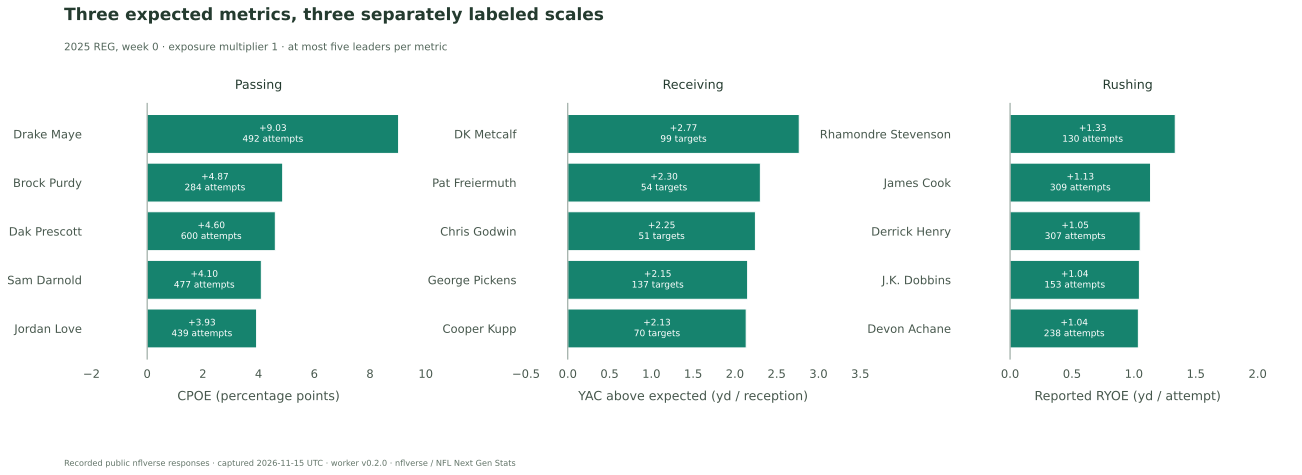

In [10]:
display(metric_scope)
display(leader_rows)
prose(
    "The workload selection retains "
    + ", ".join(
        f"**{int(r.selected_rows)}/{int(r.source_rows)} {r.metric.lower()} rows**"
        for r in metric_scope.itertuples()
    )
    + ". The figures display at most five within each metric. These are descriptive selections within returned tracking populations, not all NFL players."
)
fig, axes = plt.subplots(1, 3, figsize=(19, 7))
settings = [
    ("Passing", "CPOE (percentage points)", (-2, 10), "attempts"),
    ("Receiving", "YAC above expected (yd / reception)", (-0.5, 3.5), "targets"),
    ("Rushing", "Reported RYOE (yd / attempt)", (-0.4, 2.3), "attempts"),
]
for ax, (metric, label, limits, exposure) in zip(axes, settings, strict=True):
    rows = leader_rows[leader_rows.metric == metric]
    bars = ax.barh(rows.player_display_name, rows.value, color="#16836e")
    ax.bar_label(
        bars,
        labels=[f"{r.value:+.2f}\n{int(r.exposure)} {exposure}" for r in rows.itertuples()],
        label_type="center",
        color="white",
        fontsize=9,
    )
    ax.set_title(metric, pad=14)
    ax.set_xlim(*limits)
    ax.invert_yaxis()
    ax.axvline(0, color="#899b92", linewidth=1)
    ax.set_xlabel(label)
finish(
    fig,
    title="Three expected metrics, three separately labeled scales",
    subtitle=f"2025 REG, week 0 · exposure multiplier {EXPOSURE_MULTIPLIER} · at most five leaders per metric",
    source=SOURCE + " · nflverse / NFL Next Gen Stats",
    name=f"expected-leaders-{EXPOSURE_MULTIPLIER}",
)

### Do not invent a common rushing denominator

Compute two **diagnostic residuals**, leaving the provider’s values untouched:

1. `all rushing yards − expected rushing yards − reported yards over expected`;
2. `reported yards over expected per attempt − reported total yards over expected / all rush attempts`.

If all columns covered the same events with simple additive definitions, these would be zero. Their observed differences show that this reconstruction is not justified by the exposed columns. The returned table does not identify the missing eligibility or modeling detail, so we cannot attribute the discrepancy to a particular play type or repair it by guessing a denominator.

In [11]:
%%sql rushing_audit <<
SELECT player_gsis_id,player_display_name,team,rush_attempts,rush_yards,expected_rush_yards,
 rush_yards_over_expected,rush_yards_over_expected_per_att,
 rush_yards-expected_rush_yards-rush_yards_over_expected AS total_residual_yards,
 rush_yards_over_expected_per_att-rush_yards_over_expected/nullif(rush_attempts,0) AS rate_residual
FROM rushing ORDER BY abs(total_residual_yards) DESC,player_gsis_id;

,player_gsis_id,player_display_name,team,rush_attempts,rush_yards,expected_rush_yards,rush_yards_over_expected,rush_yards_over_expected_per_att,total_residual_yards,rate_residual
0,00-0036919,Kenneth Gainwell,PIT,114,537,407.310219,59.689781,0.547613,70.0,0.024018
1,00-0037256,Rachaad White,TB,132,572,549.552916,-31.552916,-0.248448,54.0,-0.009411
2,00-0032764,Derrick Henry,BAL,307,1595,1224.438978,319.561022,1.051188,51.0,0.010272
3,00-0033293,Aaron Jones,MIN,132,548,524.845591,-12.845591,-0.099578,36.0,-0.002263
4,00-0038134,Kenneth Walker III,SEA,221,1027,939.458927,53.541073,0.250192,34.0,0.007925
5,00-0036973,Travis Etienne,JAX,260,1107,1035.333253,40.666747,0.161376,31.0,0.004965
6,00-0039384,Tyrone Tracy,NYG,176,740,692.089440,17.910560,0.105356,30.0,0.003592
7,00-0036158,J.K. Dobbins,DEN,153,772,586.294952,156.705048,1.044700,29.0,0.020484


Among **51 rushing rows**, the largest absolute total residual is **70.0 yards** and the largest per-attempt residual is **0.0240 yards per attempt**. The chart uses the same eight players in both panels, selected by the total residual. It is a compatibility diagnostic, not a ranking of player ability or a claim that the source is wrong. The multiplier does not change this audit.

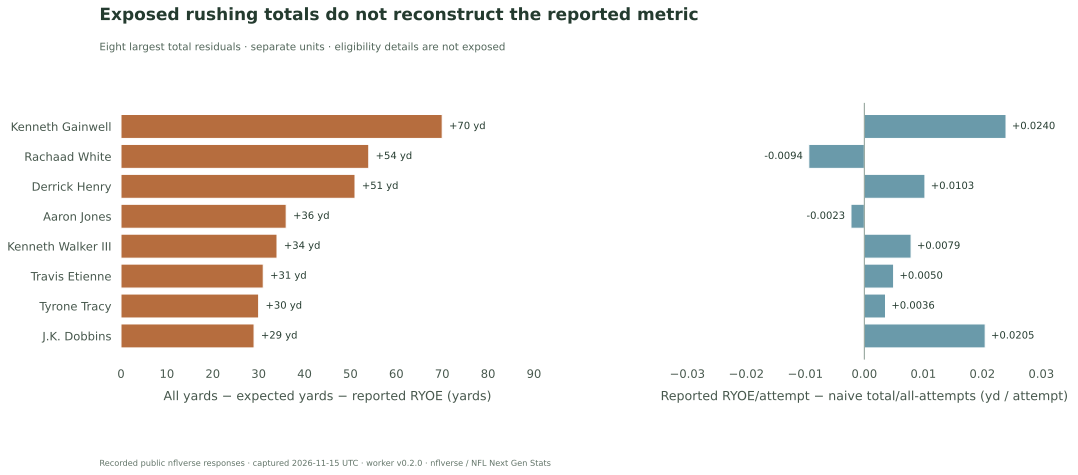

In [12]:
display(rushing_audit.head(8))
prose(
    f"Among **{len(rushing_audit)} rushing rows**, the largest absolute total residual is **{rushing_audit.total_residual_yards.abs().max():.1f} yards** and the largest per-attempt residual is **{rushing_audit.rate_residual.abs().max():.4f} yards per attempt**. The chart uses the same eight players in both panels, selected by the total residual. It is a compatibility diagnostic, not a ranking of player ability or a claim that the source is wrong. The multiplier does not change this audit."
)
rows = rushing_audit.head(8)
y = np.arange(len(rows))
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
axes[0].barh(y, rows.total_residual_yards, color="#b66d3e")
axes[1].barh(y, rows.rate_residual, color="#6a9aaa")
axes[0].set_yticks(y, rows.player_display_name)
axes[0].invert_yaxis()
for i, r in enumerate(rows.itertuples()):
    axes[0].text(
        r.total_residual_yards + 1.5, i, f"{r.total_residual_yards:+.0f} yd", va="center", fontsize=10
    )
    axes[1].text(
        r.rate_residual + (0.001 if r.rate_residual >= 0 else -0.001),
        i,
        f"{r.rate_residual:+.4f}",
        va="center",
        ha="left" if r.rate_residual >= 0 else "right",
        fontsize=10,
    )
axes[0].set_xlim(0, 90)
axes[0].set_xlabel("All yards − expected yards − reported RYOE (yards)")
axes[1].set_xlim(-0.035, 0.035)
axes[1].set_xlabel("Reported RYOE/attempt − naive total/all-attempts (yd / attempt)")
axes[1].axvline(0, color="#899b92", linewidth=1)
finish(
    fig,
    title="Exposed rushing totals do not reconstruct the reported metric",
    subtitle="Eight largest total residuals · separate units · eligibility details are not exposed",
    source=SOURCE + " · nflverse / NFL Next Gen Stats",
    name="rushing-population-gap",
)

In [13]:
%%sql checks <<
SELECT 'Three metric populations' AS check_name,count(DISTINCT metric)=3 AS passed FROM metric_rows
UNION ALL SELECT 'Passing row keys',count(*)=count(DISTINCT player_gsis_id) AND bool_and(season=2025 AND week=0 AND season_type='REG') FROM passing
UNION ALL SELECT 'Receiving row keys',count(*)=count(DISTINCT player_gsis_id) AND bool_and(season=2025 AND week=0 AND season_type='REG') FROM receiving
UNION ALL SELECT 'Rushing row keys',count(*)=count(DISTINCT player_gsis_id) AND bool_and(season=2025 AND week=0 AND season_type='REG') FROM rushing
UNION ALL SELECT 'Positive observed exposure',bool_and(exposure>0 AND value IS NOT NULL AND isfinite(value)) FROM metric_rows
UNION ALL SELECT 'Completion counts and expected percent bounded',bool_and(completions BETWEEN 0 AND attempts AND expected_completion_percentage BETWEEN 0 AND 100) FROM passing
UNION ALL SELECT 'Passing rate identity',max(abs(completion_percentage-100.0*completions/attempts))<1e-9 FROM passing
UNION ALL SELECT 'Passing expected-difference identity',max(abs(completion_percentage-expected_completion_percentage-completion_percentage_above_expectation))<1e-9 FROM passing
UNION ALL SELECT 'Receiving expected-difference identity',max(abs(avg_yac-avg_expected_yac-avg_yac_above_expectation))<1e-9 FROM receiving
UNION ALL SELECT 'Selection uses each named exposure',bool_and(exposure>=base_threshold*{{EXPOSURE_MULTIPLIER}}) FROM selected
UNION ALL SELECT 'Every selected population nonempty',count(DISTINCT metric)=3 FROM selected
UNION ALL SELECT 'Rushing diagnostic retains reported mismatch',max(abs(rush_yards-expected_rush_yards-rush_yards_over_expected))>0 FROM rushing
UNION ALL SELECT 'Reported rushing rate is not naively replaced',max(abs(rush_yards_over_expected_per_att-rush_yards_over_expected/rush_attempts))>0 FROM rushing;

In [14]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + source.audit())
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-03.json").write_text(
    json.dumps(
        {
            "parameters": {"DATA_MODE": DATA_MODE, "EXPOSURE_MULTIPLIER": EXPOSURE_MULTIPLIER},
            "identities": identities.to_dict("records"),
            "leader_rows": leader_rows.to_dict("records"),
            "metric_scope": metric_scope.to_dict("records"),
            "rushing_audit": rushing_audit.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,Three metric populations,True
1,Passing row keys,True
2,Receiving row keys,True
3,Rushing row keys,True
4,Positive observed exposure,True
5,Completion counts and expected percent bounded,True
6,Passing rate identity,True
7,Passing expected-difference identity,True
8,Receiving expected-difference identity,True
9,Selection uses each named exposure,True


**All 13 SQL checks passed.** Exactly 3 recorded responses requested once each; no unexpected requests.

27689

### Change one thing

Change only `EXPOSURE_MULTIPLIER` from **1 to 2**. Eligible populations can only shrink: the thresholds become 400 pass attempts, 100 receiving targets and 200 rush attempts. Compare each metric’s leader list within its own units. All raw metric values and both reconstruction audits must remain identical; the rushing diagnostic figure should be byte-identical. Restore **1**. A tighter exposure rule does not establish model accuracy or statistical reliability.

In [15]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nfl](https://github.com/Query-farm/vgi-nfl)